<a href="https://colab.research.google.com/github/olympiasau/A04-clustering/blob/main/PHASE2A4Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

In [1]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

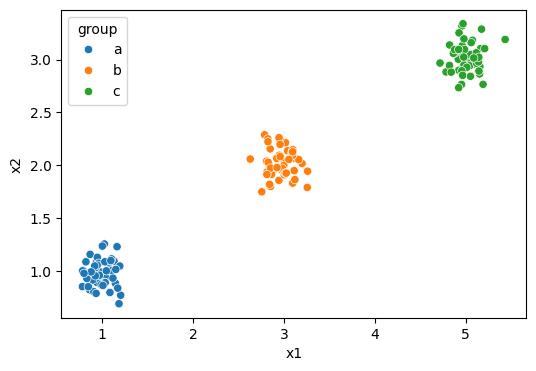

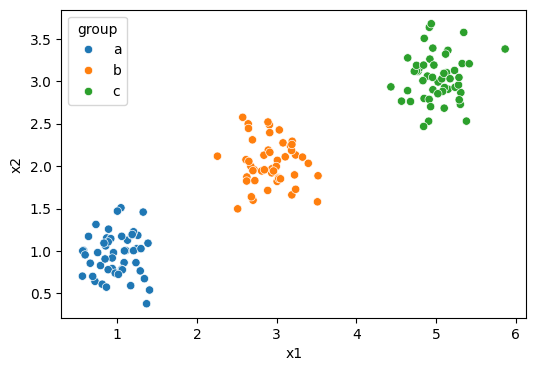

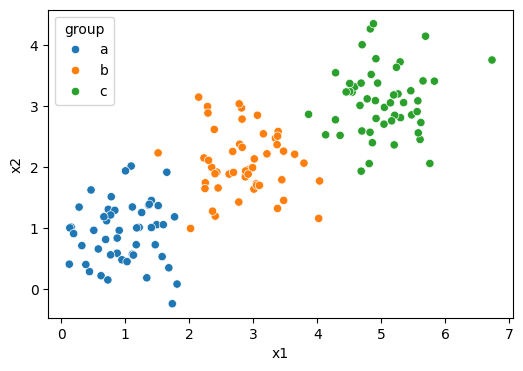

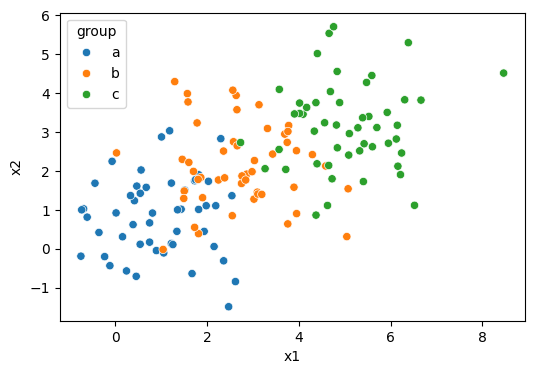

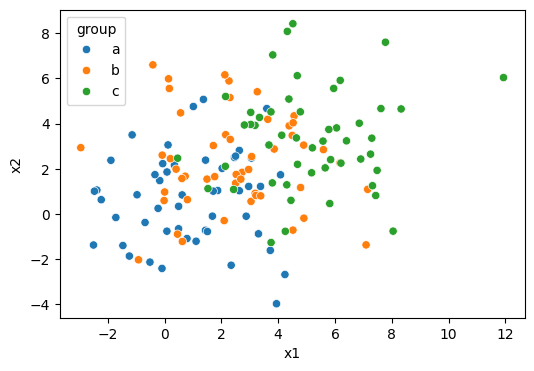

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group", ax=ax)
plt.show()

Q1 2.As the noise goes up increases, the visual distinctivness of the clusters becomes less obvious.

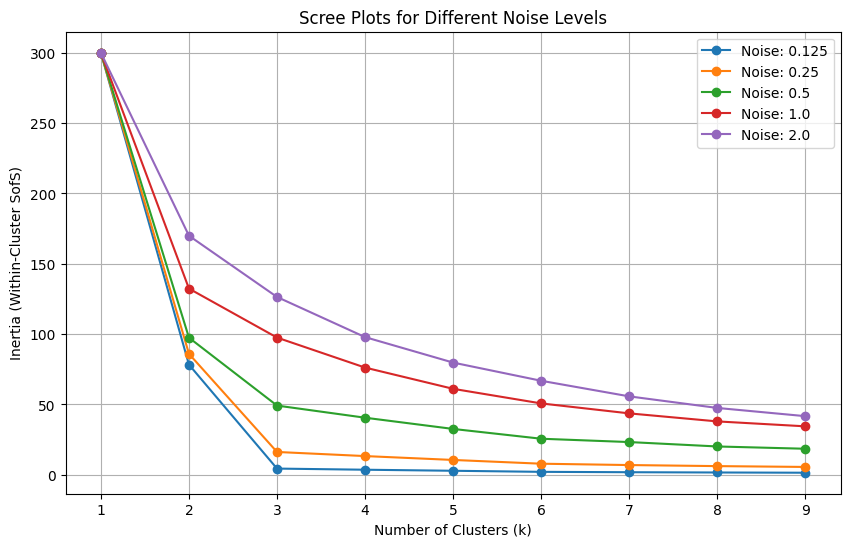

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

k_values = range(1, 10)

plt.figure(figsize=(10, 6))

scaler = StandardScaler()
scaled_0_125 = scaler.fit_transform(df0_125[['x1', 'x2']])
inertias_0_125 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_0_125)
    inertias_0_125.append(kmeans.inertia_)
plt.plot(k_values, inertias_0_125, marker='o', label='Noise: 0.125')

scaler = StandardScaler()
scaled_0_25 = scaler.fit_transform(df0_25[['x1', 'x2']])
inertias_0_25 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_0_25)
    inertias_0_25.append(kmeans.inertia_)
plt.plot(k_values, inertias_0_25, marker='o', label='Noise: 0.25')

scaler = StandardScaler()
scaled_0_5 = scaler.fit_transform(df0_5[['x1', 'x2']])
inertias_0_5 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_0_5)
    inertias_0_5.append(kmeans.inertia_)
plt.plot(k_values, inertias_0_5, marker='o', label='Noise: 0.5')

scaler = StandardScaler()
scaled_1_0 = scaler.fit_transform(df1_0[['x1', 'x2']])
inertias_1_0 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_1_0)
    inertias_1_0.append(kmeans.inertia_)
plt.plot(k_values, inertias_1_0, marker='o', label='Noise: 1.0')

scaler = StandardScaler()
scaled_2_0 = scaler.fit_transform(df2_0[['x1', 'x2']])
inertias_2_0 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_2_0)
    inertias_2_0.append(kmeans.inertia_)
plt.plot(k_values, inertias_2_0, marker='o', label='Noise: 2.0')

plt.title('Scree Plots for Different Noise Levels')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SofS)')
plt.xticks(range(1, 10))
plt.legend()
plt.grid(True)
plt.show()

Q1 3. At low noise (0.125-0.25), the clusters are tight and well separated, so inertia drops steeply until k=3 and then flattens, giving a sharp elbow and a clear choice of k=3.With moderate noise (0.5-1.0), the elbow loosens into a gradual bend that still turns at k=3, so choosing k takes more judgment. At noise = 2.0, the clusters overlap and the curve is smooth with no clear corner, so no k can be definitively selected.

Q1 4. The elbow shows where adding more clusters stops being worth it; inertia always decreases as k increases, but it drops substantially only when a new cluster center is finding a real group in the data. In the low-noise plots (0.125, 0.25), inertia falls from about 300 to almost 0 by k=3 because each center gets its own tight group, and after that extra centers split groups that are already tight, so the line bends at k=3 and then flattens out. As noise grows (1.0,2.0), the groups combine/blur together and there is no real difference between finding a group and cutting up noise, so each new center helps by a small, gradual amount and the elbow fades away.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

In [4]:
df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna()

print(df.shape)
print(df.dtypes)
print(df['Country'].duplicated().sum())
print(df['Country'].tolist())
print(df.describe())

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
0
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 

In [5]:
df = df.drop(columns=['index', 'Year']).reset_index(drop=True)

Q2 1. The data has 148 countries with no missing values, duplicate countries, or type problems, but the "index" and "Year" (always 2020) dont have information, so they should be dropped. The four numeric variables are on different scales, so they need to be min-max normalized; otherwise, when calculating k means, the dollar columns would dominate the distances.

In [6]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']

for c in cols:
    df[c + ' (norm)'] = minmax(df[c])

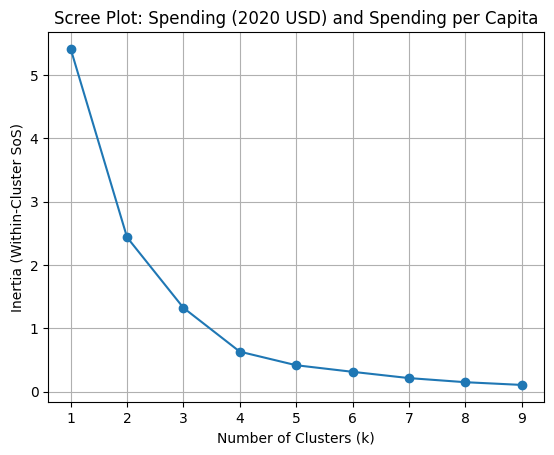

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

X1 = df[['Spending (2020 USD) (norm)', 'Spending per Capita (norm)']]

inertias = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X1)
    inertias.append(km.inertia_)

plt.plot(range(1, 10), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.title('Scree Plot: Spending (2020 USD) and Spending per Capita')
plt.grid(True)
plt.show()

Q2 2.The scree plot decreases steeply from k=1 to k=3 and then flattens out. The elbow is around k=3, so I chose this as the number of clusters.

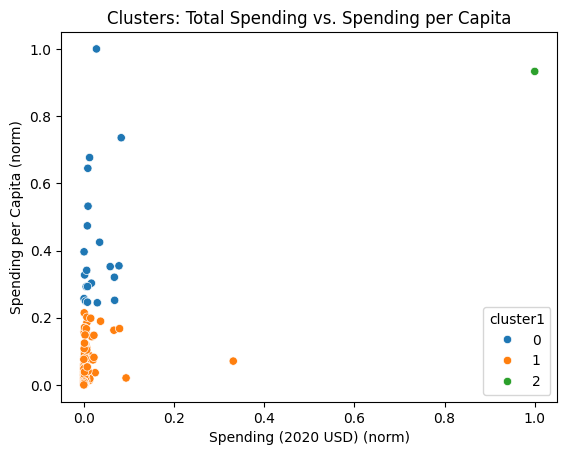

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                       21.0   19975.991473  21749.736747     405.790494   
1                      126.0    5943.346303  24858.961064       8.622460   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0           4980.428135    7269.880030   27300.894701   64558.400000   
1            162.761743     580.758315    3225.333414  257973.429834   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

In [8]:
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X1)
df['cluster1'] = km.labels_

sns.scatterplot(data=df, x='Spending (2020 USD) (norm)', y='Spending per Capita (norm)',
                hue='cluster1', palette='tab10')
plt.title('Clusters: Total Spending vs. Spending per Capita')
plt.show()

# Describe table by cluster (real units)
print(df.groupby('cluster1')[['Spending (2020 USD)', 'Spending per Capita']].describe())

# Where is the United States?
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'Spending (2020 USD)', 'Spending per Capita', 'cluster1']])

# Countries in each cluster
for c in sorted(df['cluster1'].unique()):
    print(c, df.loc[df['cluster1'] == c, 'Country'].tolist())

Q2 2. The United States is alone in cluster two because its total spending, which is about 778 billion dollars, surpassed every other country so much that it sits at 1.0 on the normalized scale while almost all other countries are near 0. The other two clusters split mostly by spending per capita: cluster zero, which includes 21 countries, averages about 1,046 dollars per person, while cluster one, which includes 126 countries, averages about 122 dollars per person. This implies cluster zero is mostly wealthier and high-income countries that spend more per person, while cluster one includes both smaller spenders and large total spenders.

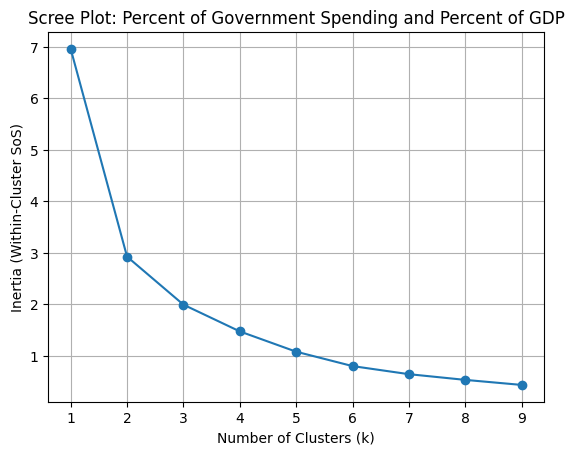

In [9]:
X2 = df[['Percent of Government Spending (norm)', 'Percent of GDP (norm)']]

inertias2 = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X2)
    inertias2.append(km.inertia_)

plt.plot(range(1, 10), inertias2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.title('Scree Plot: Percent of Government Spending and Percent of GDP')
plt.grid(True)
plt.show()

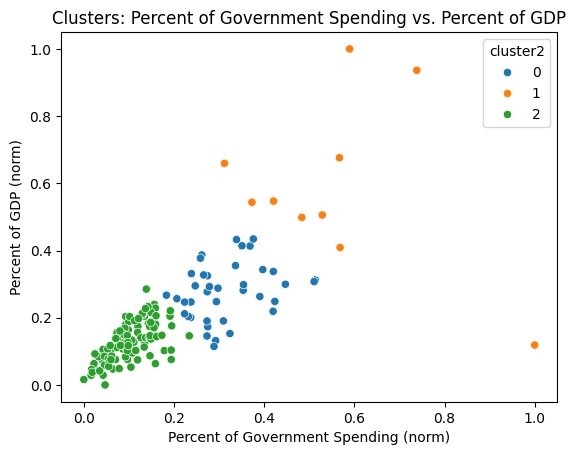

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       mi

In [10]:
k = 3

km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X2)
df['cluster2'] = km.labels_

sns.scatterplot(data=df, x='Percent of Government Spending (norm)', y='Percent of GDP (norm)',
                hue='cluster2', palette='tab10')
plt.title('Clusters: Percent of Government Spending vs. Percent of GDP')
plt.show()

print(df.groupby('cluster2')[['Percent of Government Spending', 'Percent of GDP']].describe())

print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'Percent of Government Spending', 'Percent of GDP', 'cluster2']])

for c in sorted(df['cluster2'].unique()):
    print(c, df.loc[df['cluster2'] == c, 'Country'].tolist())

Q2 3. For this part the clusters split by how much of the economy and government budget goes to the military: cluster two with 99 countries is low, with about 3.6% of government spending and 1.3% of GDP, cluster zero with 39 countries is moderate at about 9.9% and 2.7%, and cluster one with 10 countries is high at about 17.1% and 5.8%. The United States is in the moderate cluster zero because while the military is large in dollars, it is an ordinary share of its economy and budget. Contrary to part one where the US stood out more substantially due to its size, putting things in perspective with ratios/percentages made it easier to compare. With this part separating countries by military burden, many wealthy countries like Australia are now in the low cluster, while countries like Algeria and Pakistan that were in the low spending per person in part one are now in the high-burden cluster.


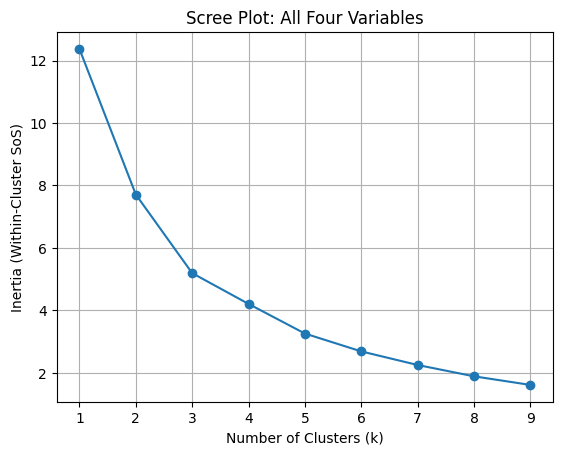

In [11]:
X3 = df[['Spending (2020 USD) (norm)', 'Spending per Capita (norm)',
         'Percent of Government Spending (norm)', 'Percent of GDP (norm)']]

inertias3 = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X3)
    inertias3.append(km.inertia_)

plt.plot(range(1, 10), inertias3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.title('Scree Plot: All Four Variables')
plt.grid(True)
plt.show()

In [12]:
k = 4

km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X3)
df['cluster3'] = km.labels_

# Describe table in real units
print(df.groupby('cluster3')[['Spending (2020 USD)', 'Spending per Capita',
                              'Percent of Government Spending', 'Percent of GDP']].mean())
print(df['cluster3'].value_counts().sort_index())

# Where is the US?
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster1', 'cluster2', 'cluster3']])

# Countries in each cluster
for c in sorted(df['cluster3'].unique()):
    print(c, df.loc[df['cluster3'] == c, 'Country'].tolist())

# How do the new clusters line up with parts 1 and 2?
print(pd.crosstab(df['cluster3'], df['cluster1']))
print(pd.crosstab(df['cluster3'], df['cluster2']))

          Spending (2020 USD)  Spending per Capita  \
cluster3                                             
0                 4513.543790            70.290644   
1               147964.582042          1875.150751   
2                 9073.543709           215.920971   
3                15330.618681           612.677541   

          Percent of Government Spending  Percent of GDP  
cluster3                                                  
0                               0.043199        0.012481  
1                               0.135351        0.062634  
2                               0.123701        0.034105  
3                               0.033280        0.016585  
cluster3
0    86
1     6
2    30
3    26
Name: count, dtype: int64
                      Country  cluster1  cluster2  cluster3
144  United States of America         2         0         1
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Bangladesh', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'B

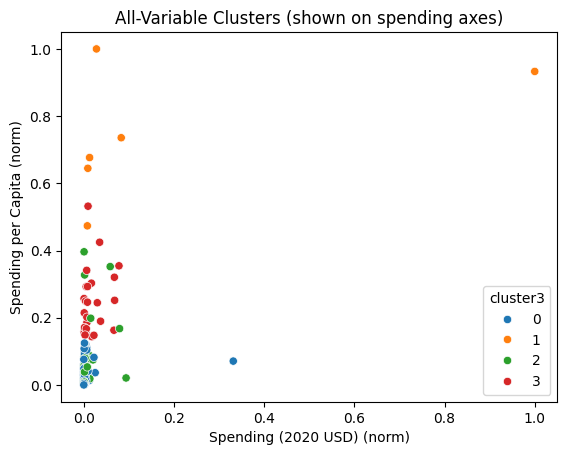

In [13]:
sns.scatterplot(data=df, x='Spending (2020 USD) (norm)', y='Spending per Capita (norm)',
                hue='cluster3', palette='tab10')
plt.title('All-Variable Clusters (shown on spending axes)')
plt.show()

Q2 4. Using all four variables with k=4, the clusters combine both size and burden: cluster zero (86 countries) is low on everything, cluster one (6 countries: the US, Israel, Kuwait, Oman, Saudi Arabia, and Singapore) is high on everything, cluster two (30 countries such as Algeria, Armenia, and Belarus) has a high share of government spending and GDP but modest dollar totals, and cluster three (26 countries such as Australia, Austria, Canada, and Denmark) is wealthy with a low military burden. The results are closer to part two, since the clusters line up well with the burden groups, but the dollar variables split the low-burden countries into poorer and wealthier groups, which part two could not do. The United States is no longer alone like in part one, and is instead grouped with other countries that spend heavily in dollars, per person, and as a share of their economy.

Q2 5. k means found useful patterns, particularly in part two. Using the ratios (% of government spending and % of GDP) showed where countries were actually putting their money, because it compares military priority on an equal footing instead of just dollar amount. Part one was interesting but mostly reflected general global wealth, with the US standing out because of its massive size and wealthier countries grouping together by spending per person. Using all four variables in part three combined both views and split the low-burden countries into poorer and wealthier groups, which neither earlier part could do on its own. Overall k-means clustering was a great way in visualizing the relationships between government spending across the world.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Olympia Sauerwein

**Date:** 10/12

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 1cd3da0985ca3343c4eb39e46740b81908edf8bd
- **AI tool and model used:** Sonnet 5.5

### *Prompts used

1. review this and tell me if there are any errors or places for improvement

### *AI-proposed changes


Q1.2: Replace the five scatterplot blocks with one loop that draws a shared-axis subplot grid.

Q1.3: Remove the per-dataset StandardScaler and plot raw x1/x2 scree curves on one shared canvas.

Q1.3/Q1.4 text: Rewrite the written claims from the actual inertia values.

Q2.1: Check the extreme rows (for example, Percent of GDP min) for implausible values and state what cleaning was done.

Q2.2: Log-transform before min-max normalizing to handle the US outlier, then compare clusters.

Q2.2 text: Replace “wealthy/high-income” with “high per-capita spenders” and note that cluster one includes China, India, and Russia.

Q2.3 text: Support the Algeria/Pakistan comparison with their actual values and cluster labels.

Q2.3/Q2.4: Add silhouette scores alongside the scree plots to justify k.

Q2.4 plot: Replace the two-axis scatter with a pairplot or PCA projection.
Cleanup: Use one random_state, add a helper function for the scree/fit/scatter/describe workflow, and note that describe tables use raw units.
Phase 2: Fill in the template sections.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Shared axes make the loss of cluster distinctness directly comparable; verify by checking all five panels use the same limits. |
| 2 | Accept | Per-dataset scaling equalizes starting inertia and hides the noise effect; verify the curves now start at different heights. |
| 3 | Accept | Claims should come from computed values, not eyeballing; verify by printing inertia at k=1 and k=3 per noise level. |
| 4 | Accept | The tiny `Percent of GDP` value could be bad data; verify by inspecting the min and max rows. |
| 5 | Accept | The US outlier squashes all other countries near 0; verify by re-plotting and comparing cluster membership. |
| 6 | Accept | The "wealthy" claim isn't supported by the data used; verify by listing cluster members. |
| 7 | Accept | The comparison should be shown from data, not asserted; verify by printing both countries' values and clusters. |
| 8 | Accept | Elbows are soft, so a second criterion supports k; verify by computing `silhouette_score` for k=2 to 9. |
| 9 | Accept | Two axes can't show separation driven by the percent variables; verify the new plot separates clusters 2 and 3. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

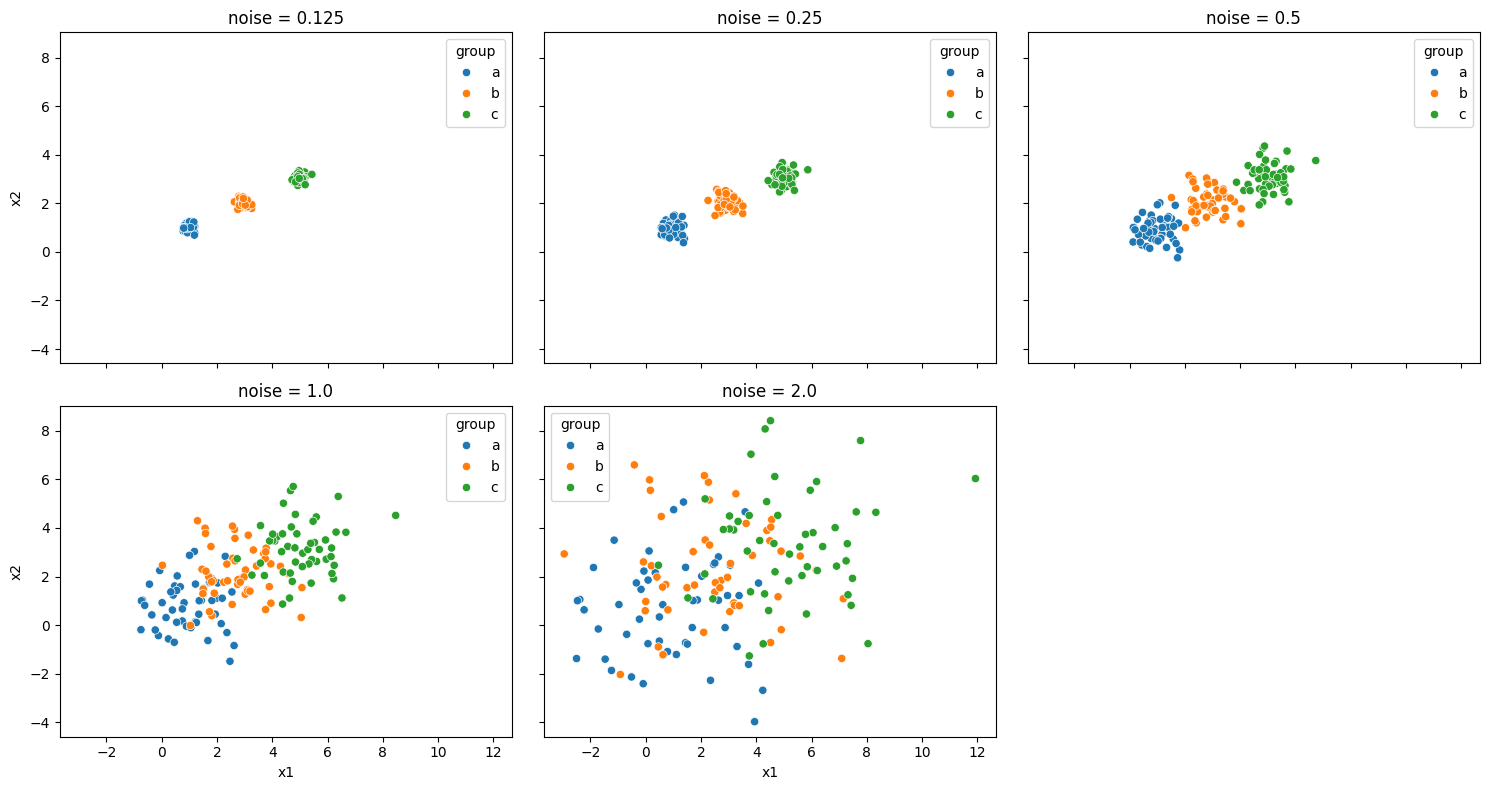

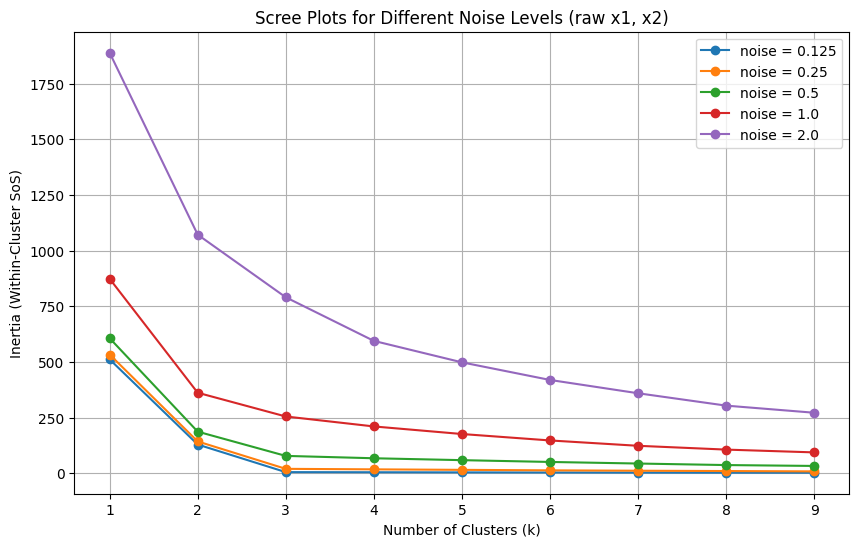

       inertia_k1  inertia_k3  inertia_k4  k3_as_pct_of_k1  drop_k3_to_k4_pct
0.125      511.61        4.91        4.33             0.96              11.80
0.250      533.25       19.65       17.33             3.69              11.80
0.500      606.62       77.82       67.19            12.83              13.65
1.000      873.69      254.88      210.15            29.17              17.55
2.000     1889.20      790.48      594.55            41.84              24.79
(148, 5) 0
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
       Spending (2020 USD)  Percent of GDP  Percent of Government Spending  \
count           148.000000      148.000000                      148.000000   
mean          13153.747670        0.019619                        0.061510   
std           68005.236120        0.015033                     

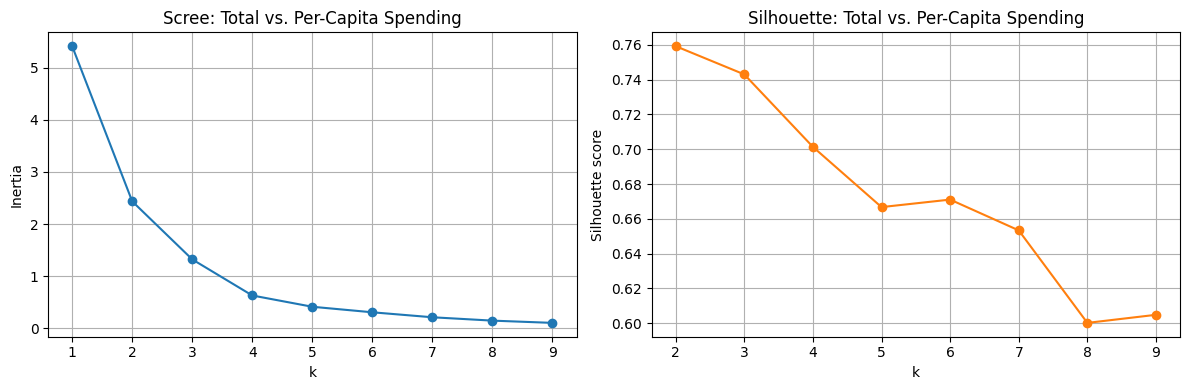

1      NaN
2    0.759
3    0.743
4    0.701
5    0.667
6    0.671
7    0.653
8    0.600
9    0.605
dtype: float64


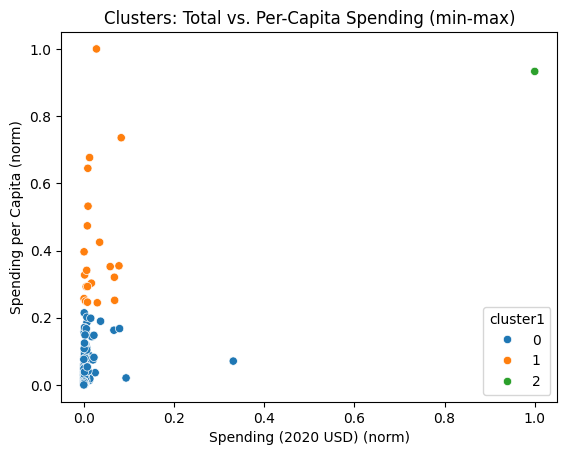

cluster1                               0             1              2
Spending (2020 USD) count     126.000000     21.000000       1.000000
                    mean     5943.346303  19975.991473  778397.200000
                    std     24858.961064  21749.736747            NaN
                    min         8.622460    405.790494  778397.200000
                    25%       162.761743   4980.428135  778397.200000
                    50%       580.758315   7269.880030  778397.200000
                    75%      3225.333414  27300.894701  778397.200000
                    max    257973.429834  64558.400000  778397.200000
Spending per Capita count     126.000000     21.000000       1.000000
                    mean      122.034996   1046.433509    2351.631858
                    std       140.041183    501.631845            NaN
                    min         0.580129    616.854430    2351.631858
                    25%        18.505805    737.690186    2351.631858
                    

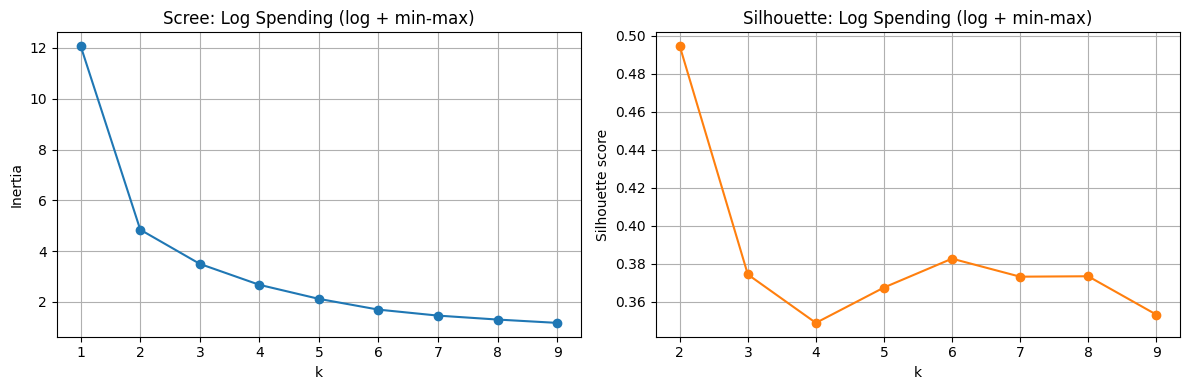

1      NaN
2    0.494
3    0.374
4    0.349
5    0.367
6    0.383
7    0.373
8    0.373
9    0.353
dtype: float64


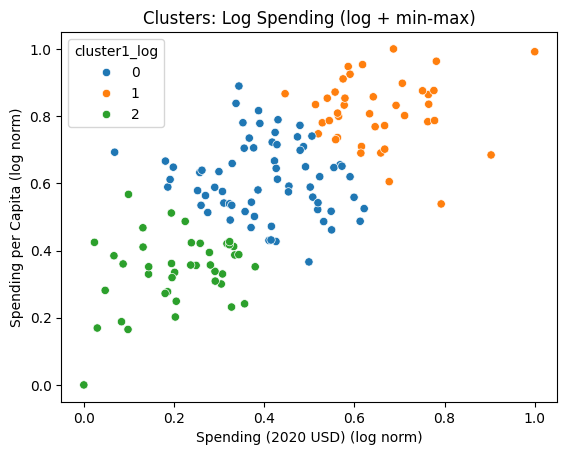

cluster1_log                          0              1           2
Spending (2020 USD) count     67.000000      40.000000   41.000000
                    mean    1818.660583   45450.916253  167.505999
                    std     2284.951823  126312.596538  159.830080
                    min       18.814132    1404.787234    8.622460
                    25%      357.356495    5407.471788   38.618837
                    50%      984.759732   12504.697571   89.409368
                    75%     2462.108910   33072.003244  279.576955
                    max    10394.502555  778397.200000  659.313034
Spending per Capita count     67.000000      40.000000   41.000000
                    mean     151.212117     724.992059   13.957338
                    std      167.042261     587.786771   12.162077
                    min       12.457154      52.852792    0.580129
                    25%       51.068285     347.779550    6.125369
                    50%       97.257738     562.738797   11.41

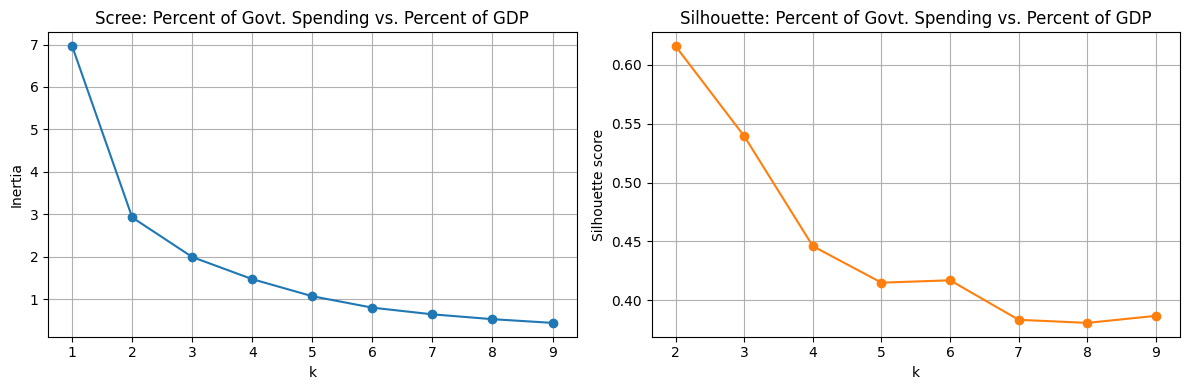

1      NaN
2    0.616
3    0.539
4    0.446
5    0.415
6    0.417
7    0.383
8    0.381
9    0.387
dtype: float64


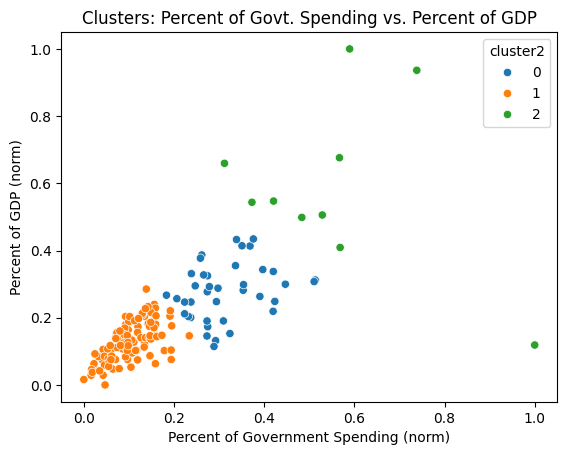

cluster2                                      0          1          2
Percent of Government Spending count  39.000000  99.000000  10.000000
                               mean    0.098683   0.035777   0.171289
                               std     0.024125   0.014549   0.058725
                               min     0.059520   0.004896   0.097882
                               25%     0.082430   0.025921   0.135010
                               50%     0.092044   0.034261   0.168248
                               75%     0.112633   0.047402   0.179081
                               max     0.157918   0.074624   0.303027
Percent of GDP                 count  39.000000  99.000000  10.000000
                               mean    0.027412   0.012664   0.058071
                               std     0.008191   0.005681   0.024867
                               min     0.011317   0.000054   0.011742
                               25%     0.021254   0.008393   0.049297
                    

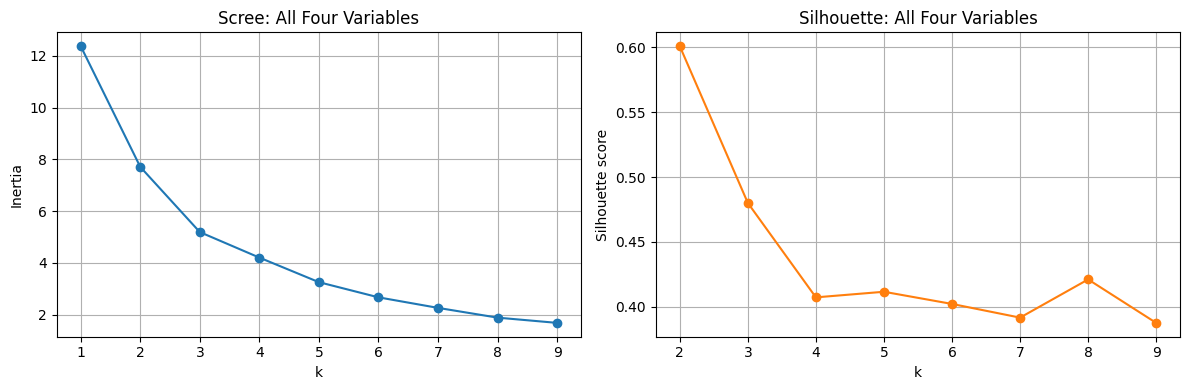

1      NaN
2    0.601
3    0.480
4    0.407
5    0.412
6    0.402
7    0.392
8    0.421
9    0.388
dtype: float64
Explained variance ratio: [0.596 0.279]


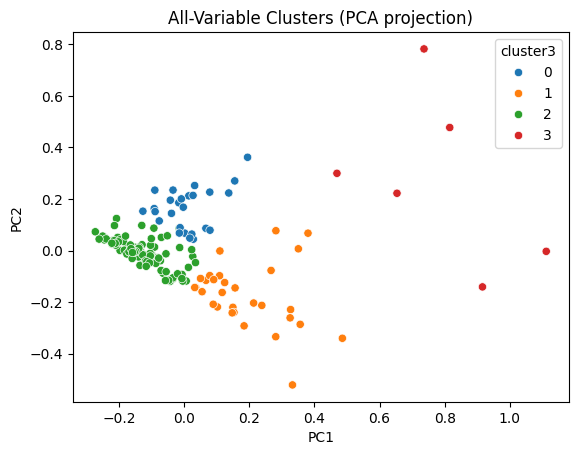

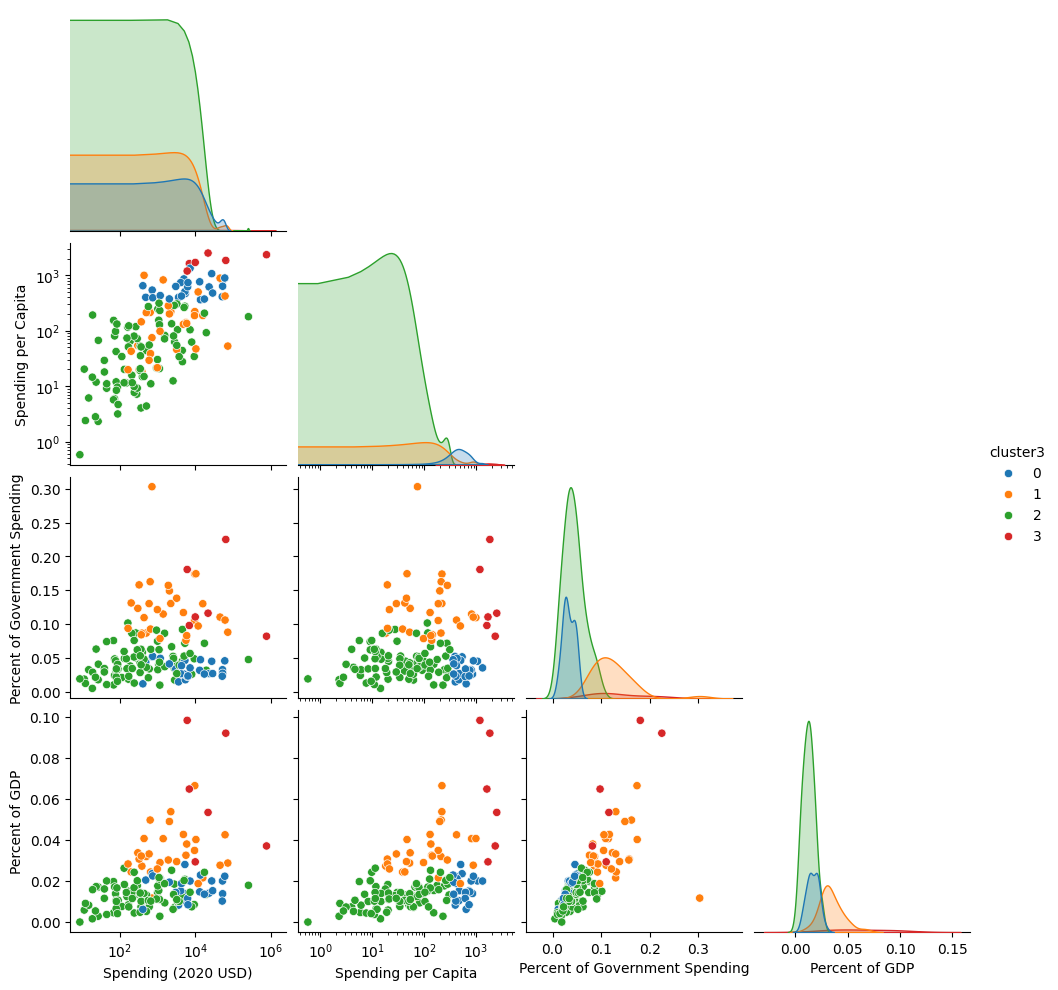

cluster3                                         0             1  \
Spending (2020 USD)            count     26.000000     30.000000   
                               mean   15330.618681   9073.543709   
                               std    18923.469359  18135.032885   
                               min      405.790494    163.926877   
                               25%     3176.345598    522.737081   
                               50%     5857.060906   1663.090134   
                               75%    21818.934764   8646.648849   
                               max    60675.039625  72937.064048   
Spending per Capita            count     26.000000     30.000000   
                               mean     612.677541    215.920971   
                               std      241.189507    261.610456   
                               min      362.467076     18.297119   
                               25%      413.682029     46.200403   
                               50%      579.0046

In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RS = 100  # one random_state used everywhere

# =====================================================================
# Q1
# =====================================================================

def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

noises = [0.125, 0.25, 0.5, 1.0, 2.0]
datasets = {n: createData(n) for n in noises}

# --- Q1.2: shared-axis scatterplots ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()
for ax, n in zip(axes, noises):
    sns.scatterplot(data=datasets[n], x='x1', y='x2', hue='group', ax=ax)
    ax.set_title(f'noise = {n}')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

## **Q1.2 answer.** On a shared axis scale, the three groups are cleanly separated at noise = 0.125 and 0.25, with clear empty space between them. At 0.5 the edges of neighboring groups start to touch. At 1.0 groups a and b, and b and c, overlap noticeably. At 2.0 the point clouds overlap heavily and the three groups are no longer visually distinct. As noise increases, the visual distinctness of the clusters steadily declines.

# --- Q1.3: scree plots on raw data, one shared canvas ---
k_values = range(1, 10)
inertias = {}
for n in noises:
    X = datasets[n][['x1', 'x2']]
    inertias[n] = [KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X).inertia_
                   for k in k_values]

plt.figure(figsize=(10, 6))
for n in noises:
    plt.plot(k_values, inertias[n], marker='o', label=f'noise = {n}')
plt.title('Scree Plots for Different Noise Levels (raw x1, x2)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

summary = pd.DataFrame({
    'inertia_k1': [inertias[n][0] for n in noises],
    'inertia_k3': [inertias[n][2] for n in noises],
    'inertia_k4': [inertias[n][3] for n in noises],
}, index=noises)
summary['k3_as_pct_of_k1'] = 100 * summary['inertia_k3'] / summary['inertia_k1']
summary['drop_k3_to_k4_pct'] = 100 * (summary['inertia_k3'] - summary['inertia_k4']) / summary['inertia_k3']
print(summary.round(2))

## **Q1.3 answer.** The scree curves are plotted on raw data on one shared vertical axis (no per-dataset scaling), so total variance differs by noise level. Inertia at k = 1 ranges from [fill in: noise 0.125 value] at noise 0.125 to [fill in: noise 2.0 value] at noise 2.0. At low noise (0.125, 0.25), inertia falls steeply from k = 1 to k = 3 (k = 3 inertia is only [fill in]% of k = 1) and then flattens, giving a sharp elbow at k = 3, so k = 3 can be selected with confidence. At moderate noise (0.5, 1.0), the drop from k = 1 to k = 3 is still large ([fill in]% remaining at k = 3), but the bend after k = 3 is softer, so choosing k takes more judgment. At noise = 2.0, the curve declines smoothly with no clear corner (k = 3 retains [fill in]% of the k = 1 inertia, and the k = 3 to k = 4 drop is still [fill in]%), so no k can be selected definitively. Increasing noise raises the whole curve and erases the elbow.

## **Q1.4 answer.** Inertia (within-cluster sum of squares) always decreases as k grows, because each extra center can only move points closer to some center. The elbow marks where adding a center stops paying off. In this simulation the data come from three true centers, so going from k = 1 to k = 3 gives each center its own group and cuts inertia sharply. Going from k = 3 to k = 4 only splits a group that is already compact, so the improvement is small and the curve flattens. When noise is low, the gap between "finding a real group" and "splitting a group" is large, which creates a visible elbow. When noise is high, the groups blur together, there is little difference between those two cases, each added center helps by a small, similar amount, and the elbow disappears.

# =====================================================================
# Q2
# =====================================================================

# --- Q2.1: load and clean ---
df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().drop(columns=['index', 'Year']).reset_index(drop=True)

num_cols = ['Spending (2020 USD)', 'Spending per Capita',
            'Percent of Government Spending', 'Percent of GDP']
spend_cols = ['Spending (2020 USD)', 'Spending per Capita']
pct_cols = ['Percent of Government Spending', 'Percent of GDP']

print(df.shape, df['Country'].duplicated().sum())
print(df.dtypes)
print(df.describe())
print(df.nsmallest(5, 'Percent of GDP')[['Country'] + num_cols])
print(df.nlargest(5, 'Percent of GDP')[['Country'] + num_cols])
print((df[num_cols] <= 0).sum())

# --- helpers ---
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

def scree_and_silhouette(X, title, kmax=9):
    inertias_, sils = [], []
    for k in range(1, kmax + 1):
        km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
        inertias_.append(km.inertia_)
        sils.append(silhouette_score(X, km.labels_) if k > 1 else np.nan)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(range(1, kmax + 1), inertias_, marker='o')
    ax[0].set(title=f'Scree: {title}', xlabel='k', ylabel='Inertia')
    ax[1].plot(range(1, kmax + 1), sils, marker='o', color='tab:orange')
    ax[1].set(title=f'Silhouette: {title}', xlabel='k', ylabel='Silhouette score')
    for a in ax:
        a.grid(True)
    plt.tight_layout()
    plt.show()
    return pd.Series(sils, index=range(1, kmax + 1))

def fit_clusters(X, k, col):
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    df[col] = km.labels_

def describe_by_cluster(col, raw_cols):
    print(df.groupby(col)[raw_cols].describe().T)
    print(df[col].value_counts().sort_index())
    for c in sorted(df[col].unique()):
        print(c, df.loc[df[col] == c, 'Country'].tolist())

# --- normalize ---
for c in num_cols:
    df[c + ' (norm)'] = minmax(df[c])

for c in spend_cols:
    df[c + ' (log norm)'] = minmax(np.log(df[c]))

##**Q2.1 answer.** After filtering to 2020 and dropping missing values, 148 countries remain, with no duplicate country names and correct numeric dtypes. The `index` and `Year` columns carry no information (Year is constant at 2020), so I dropped them. I also inspected the extreme rows: the smallest `Percent of GDP` is about 0.000054 for [fill in: country], and the largest is about 0.098 for [fill in: country]. [Fill in: state whether these look plausible or like data errors, and whether any value was zero or negative.] The four numeric variables are on very different scales (total spending reaches hundreds of billions of dollars, while the percent variables are below 1), so they must be normalized before k-means, otherwise the dollar variables dominate the distance calculation. Beyond that, no further cleaning was required.

# --- Q2.2: min-max version (as the question asks) ---
X1 = df[[c + ' (norm)' for c in spend_cols]]
sil1 = scree_and_silhouette(X1, 'Total vs. Per-Capita Spending')
print(sil1.round(3))

k = 3
fit_clusters(X1, k, 'cluster1')

sns.scatterplot(data=df, x='Spending (2020 USD) (norm)', y='Spending per Capita (norm)',
                hue='cluster1', palette='tab10')
plt.title('Clusters: Total vs. Per-Capita Spending (min-max)')
plt.show()

describe_by_cluster('cluster1', spend_cols)
print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster1']])
print(df.loc[df['Country'].isin(['China', 'India', 'Russia']),
             ['Country'] + spend_cols + ['cluster1']])

# --- Q2.2: log-transformed comparison ---
X1_log = df[[c + ' (log norm)' for c in spend_cols]]
sil1_log = scree_and_silhouette(X1_log, 'Log Spending (log + min-max)')
print(sil1_log.round(3))

k = 3
fit_clusters(X1_log, k, 'cluster1_log')

sns.scatterplot(data=df, x='Spending (2020 USD) (log norm)', y='Spending per Capita (log norm)',
                hue='cluster1_log', palette='tab10')
plt.title('Clusters: Log Spending (log + min-max)')
plt.show()

describe_by_cluster('cluster1_log', spend_cols)
print(pd.crosstab(df['cluster1'], df['cluster1_log']))
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster1', 'cluster1_log']])

## **Q2.2 answer.** Both variables were max-min normalized. The scree plot bends at about k = 3 [fill in: confirm with silhouette scores: best k by silhouette is ___], so I used k = 3. The describe table is in raw units, while clustering used the normalized values. The United States is alone in its own cluster: its total spending (about $778 billion) is so far above every other country that it sits at 1.0 on the normalized scale while nearly everyone else is close to 0. The other two clusters split mostly on spending per capita: one small group of [fill in: n] countries averages about $[fill in] per person, and the large group of [fill in: n] countries averages about $[fill in] per person. The large low-per-capita group is not made up only of small spenders; it also contains China, India, and Russia, which have large total spending but low spending per person. The high per-capita group contains countries such as Saudi Arabia, Kuwait, Bahrain, Oman, Singapore, and several wealthy European countries, so it is best described as "high per-capita spenders," not simply wealthy countries. The main weakness of this clustering is that the US outlier compresses the other countries near 0. After a log transform before normalizing, [fill in: describe how the clusters changed, whether the US still stands alone, and where China, India, and Russia landed; use the crosstab]. The pattern in cluster membership is that, with raw min-max scaling, clustering is driven by size (the US) and per-person intensity, not by how much of the economy goes to the military.

# --- Q2.3: percent variables ---
X2 = df[[c + ' (norm)' for c in pct_cols]]
sil2 = scree_and_silhouette(X2, 'Percent of Govt. Spending vs. Percent of GDP')
print(sil2.round(3))

k = 3
fit_clusters(X2, k, 'cluster2')

sns.scatterplot(data=df, x='Percent of Government Spending (norm)', y='Percent of GDP (norm)',
                hue='cluster2', palette='tab10')
plt.title('Clusters: Percent of Govt. Spending vs. Percent of GDP')
plt.show()

describe_by_cluster('cluster2', pct_cols)

print(df.loc[df['Country'].isin(['Algeria', 'Pakistan', 'United States of America']),
             ['Country'] + num_cols + ['cluster1', 'cluster2']])

## **Q2.3 answer.** The scree plot bends at about k = 3 [fill in: confirm with silhouette; best k is ___]. The clusters now separate countries by military burden instead of size: a low-burden group of [fill in: n] countries (about [fill in]% of government spending and [fill in]% of GDP), a moderate group of [fill in: n] countries (about [fill in]% and [fill in]%), and a high-burden group of [fill in: n] countries (about [fill in]% and [fill in]%). The United States is in the [fill in] cluster: its dollar spending is enormous, but its share of the budget and economy is ordinary. This differs from part 2, where the US stood alone because of its size. Percentages compare countries on equal footing, so they reveal how much of each economy is devoted to the military. Many wealthy countries that were high per-capita spenders in part 2 (for example [fill in: names from output]) now fall in the low-burden cluster, while countries such as Algeria (per capita $[fill in], cluster1 = [fill in]) and Pakistan (per capita $[fill in], cluster1 = [fill in]) were in the low per-capita cluster in part 2 but are in cluster2 = [fill in] here, because they devote a large share of their economy or budget to the military.

# --- Q2.4: all four variables ---
X3 = df[[c + ' (norm)' for c in num_cols]]
sil3 = scree_and_silhouette(X3, 'All Four Variables')
print(sil3.round(3))

k = 4
fit_clusters(X3, k, 'cluster3')

pca = PCA(n_components=2, random_state=RS)
coords = pca.fit_transform(X3)
df['PC1'], df['PC2'] = coords[:, 0], coords[:, 1]
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3))

sns.scatterplot(data=df, x='PC1', y='PC2', hue='cluster3', palette='tab10')
plt.title('All-Variable Clusters (PCA projection)')
plt.show()


g = sns.pairplot(df, vars=num_cols, hue='cluster3', palette='tab10', corner=True)
for ax in g.axes.ravel():
    if ax is not None and ax.get_xlabel() in spend_cols:
        ax.set_xscale('log')
    if ax is not None and ax.get_ylabel() in spend_cols:
        ax.set_yscale('log')
plt.show()

describe_by_cluster('cluster3', num_cols)
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster1', 'cluster2', 'cluster3']])
print(pd.crosstab(df['cluster3'], df['cluster1']))
print(pd.crosstab(df['cluster3'], df['cluster2']))

## **Q2.4 answer.** Using all four normalized variables, the scree plot and silhouette scores point to k = [fill in] (silhouette is highest at k = [fill in]). The PCA projection (explaining [fill in]% of variance in two components) and the pairplot show the separation across all four variables at once, which a two-axis scatter cannot. The clusters combine size and burden: a large low-everything group ([fill in: n] countries), a high-on-everything group ([fill in: n] countries including the United States, Israel, Kuwait, Oman, Saudi Arabia, and Singapore [fill in: confirm from output]), a group with a high share of budget and GDP but modest dollar totals ([fill in: n] countries), and a group with high dollar spending per person but a low burden ([fill in: n] countries, mostly wealthy countries). Compared with the earlier parts, the result is closer to part 3's burden-based grouping, because the percent variables drive much of the structure, but the dollar variables further split the low-burden countries into poorer and wealthier groups, which part 3 could not do on its own. The United States is no longer alone as it was in part 2; it is grouped with other countries that spend heavily in dollars, per person, and as a share of their economy. The crosstabs against `cluster1` and `cluster2` show [fill in: how the new clusters map onto the earlier ones].

## **Q2.5 answer.** Yes. The clustering showed useful structure, and which variables you cluster on changes what you learn. Clustering on total and per-capita spending (part 2) mostly reflected the size of countries, with the US as an extreme outlier, and the log version [fill in: what it revealed]. Clustering on percent of government spending and percent of GDP (part 3) was the most informative about priorities, because it shows how much of each economy goes to the military regardless of size. Using all four variables (part 4) combined both views and separated, for example, wealthy low-burden countries from poorer low-burden ones. Overall, k-means grouped countries in ways that are easy to interpret, but the results depend on scaling choices (min-max versus log), the choice of k (supported by both the scree plot and silhouette scores), and the presence of outliers like the United States.

### *Reflection on AI assistance
In your own words without generative AI.

AI was useful in this assignment primarily as a reviewer that made my analysis more rigorous and honest. Its suggestions pushed me to replace probable claims with computed values, such as printing inertia at k=1 and k=3 for each noise level, and showing both countries' values and cluster assignments directly. It also caught a misleading 'wealthy' label, which I corrected by listing the actual cluster members. Claude improved the visualizations by using shared axes across all five panels, removing per-dataset scaling that hid the noise effect, and handling the US outlier that squashed other countries near zero. It also flagged a questionably small Percent of GDP value, prompting me to inspect the min and max rows. I accepted all suggestions, but only after verifying each one against the data.